Name:Rajat Kumar Majumdar 

Roll no. 49

CU240251642

subject : computer vision


Experiment No. 6

Experiment Name:

Implementation and Comparative Analysis of Image Segmentation Techniques using Python
and OpenCV

Aim:  
To implement and evaluate various image segmentation techniques for partitioning digital
images into meaningful regions, thereby facilitating object localization, scene understanding, and subsequent computer vision tasks.

Purpose:
Image segmentation is one of the most important stages in computer vision, where an image is divided into multiple meaningful regions or objects based on pixel intensity, color, texture, or boundaries. Effective segmentation simplifies image analysis by isolating the regions of interest (ROI), making tasks such as object detection, medical diagnosis, autonomous
navigation, and industrial inspection more accurate and efficient.
In this experiment, students will implement multiple image segmentation techniques, including
Thresholding, Otsu's Thresholding, Adaptive Thresholding, Watershed Segmentation, and KMeans Clustering, and compare their performance on real-world images.
Prerequisites
• Basic knowledge of Digital Image Processing
• Familiarity with Python programming
• Python libraries: OpenCV (cv2), NumPy, Matplotlib, and Scikit-learn
• Understanding of grayscale images, image histograms, and clustering concepts
• Jupyter Notebook, Google Colab, or Visual Studio Code
Steps
1. Import the required Python libraries and load a real-world image such as a medical
image, satellite image, or natural scene.
2. Convert the image into grayscale and perform basic preprocessing to reduce noise using
Gaussian Blur.
3. Apply Global Thresholding to separate foreground objects from the background and
observe the segmentation results.
4. Implement Otsu's Thresholding to automatically determine the optimal threshold value
and compare it with global thresholding.
5. Apply Adaptive Thresholding to segment images with uneven illumination conditions.
6. Implement the Watershed Segmentation algorithm to separate overlapping or touching
objects within the image.
7. Apply K-Means Clustering for color-based image segmentation by grouping pixels into
distinct clusters.
8. Compare the segmentation outputs obtained from different techniques based on object
boundaries, accuracy, and computational efficiency.
9. Visualize and analyze the segmented images to identify the most suitable technique for
the selected dataset.
10. Summarize the observations and discuss the role of image segmentation in advanced
computer vision applications.
Questions
1. What is image segmentation? Why is it considered a fundamental step in computer
vision?
2. Differentiate between Image Segmentation and Image Classification.
3. Explain the working principle of Global Thresholding, Otsu's Thresholding, and
Adaptive Thresholding.
4. What is the Watershed Algorithm? Why is it useful for separating overlapping objects?
5. How is K-Means Clustering applied to image segmentation?
6. Compare threshold-based segmentation and clustering-based segmentation techniques.
7. What challenges are encountered while segmenting images with complex backgrounds
or varying illumination?
8. Mention five real-world applications where image segmentation plays a critical role.
9. How does image segmentation improve the performance of object detection and image
recognition systems?
10. Compare traditional image segmentation techniques with deep learning-based
segmentation methods such as U-Net and Mask R-CNN.


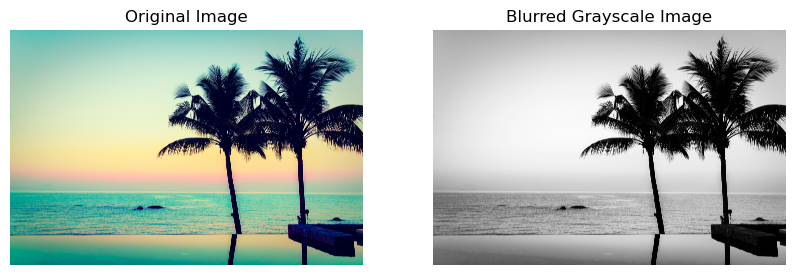

In [2]:
# Step 1 & 2: Import Libraries, Load Image, and Preprocess

import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Load a real-world image (Replace 'sample.jpg' with your image path)
# If you don't have an image, you can download a sample coin/cell image.
image_path = 'img2.jpg' 
img = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 2. Convert to grayscale and apply Gaussian Blur to reduce noise
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img_blur = cv2.GaussianBlur(img_gray, (5, 5), 0)

# Visualize the preprocessing step
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_blur, cmap='gray')
plt.title("Blurred Grayscale Image")
plt.axis('off')
plt.show()


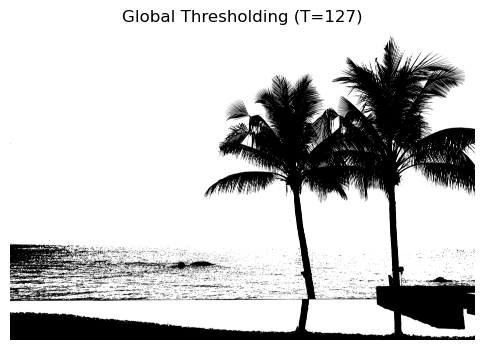

In [3]:
# 3. Apply Global Thresholding (Binary thresholding at a fixed value of 127)

fixed_thresh_val = 127
_, thresh_global = cv2.threshold(img_blur, fixed_thresh_val, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(6, 6))
plt.imshow(thresh_global, cmap='gray')
plt.title(f"Global Thresholding (T={fixed_thresh_val})")
plt.axis('off')
plt.show()


Otsu's Automatically Calculated Threshold: 111.0


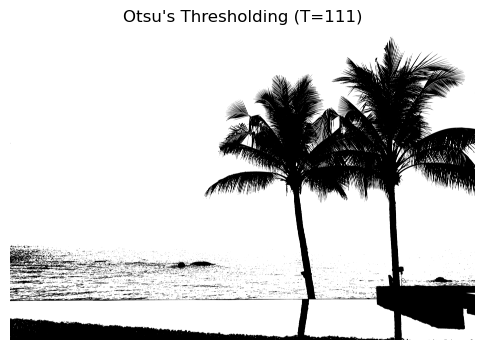

In [4]:
# 4. Implement Otsu's Thresholding
otsu_thresh_val, thresh_otsu = cv2.threshold(img_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print(selected_val := f"Otsu's Automatically Calculated Threshold: {otsu_thresh_val}")

plt.figure(figsize=(6, 6))
plt.imshow(thresh_otsu, cmap='gray')
plt.title(f"Otsu's Thresholding (T={int(otsu_thresh_val)})")
plt.axis('off')
plt.show()


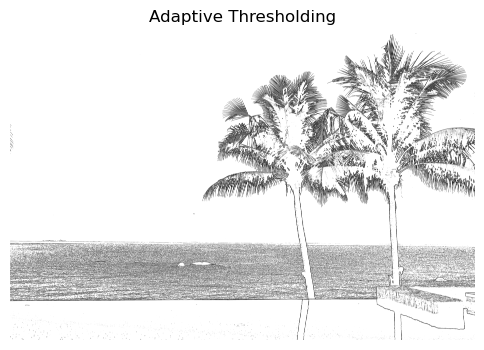

In [5]:
# 5. Apply Adaptive Thresholding (Gaussian variant)
thresh_adaptive = cv2.adaptiveThreshold(
    img_blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2
)

plt.figure(figsize=(6, 6))
plt.imshow(thresh_adaptive, cmap='gray')
plt.title("Adaptive Thresholding")
plt.axis('off')
plt.show()


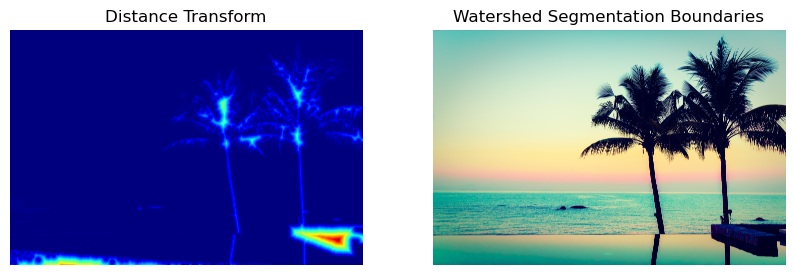

In [6]:
# 6. Watershed Segmentation

# Find rough foreground using Otsu's thresholding
_, thresh = cv2.threshold(img_blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Remove noise using morphological opening
kernel = np.ones((3,3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# Find sure background area
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Find sure foreground area using Distance Transform
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, 0)

# Find unknown region (overlapping boundaries)
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)

# Label markers for the components
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1 # Add one to all labels so that sure background is not 0, but 1
markers[unknown == 255] = 0 # Mark the region of unknown with 0

# Apply Watershed
img_watershed_input = img.copy()
markers = cv2.watershed(img_watershed_input, markers)

# Draw boundaries in red on the original image
img_watershed_output = img_rgb.copy()
img_watershed_output[markers == -1] = [255, 0, 0]

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(dist_transform, cmap='jet')
plt.title("Distance Transform")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_watershed_output)
plt.title("Watershed Segmentation Boundaries")
plt.axis('off')
plt.show()


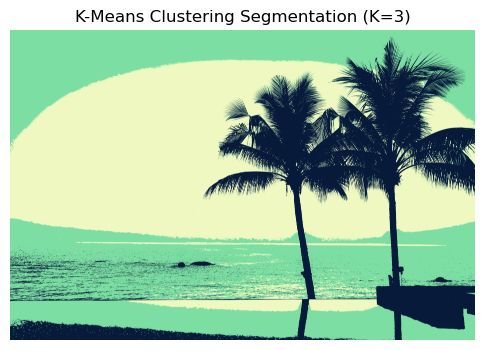

In [7]:
# 7. Apply K-Means Clustering for Color-Based Segmentation
K = 3 # Number of clusters (Change this based on your image complexity)

# Reshape the image into a 2D array of pixels (M features, where M=3 for R,G,B)
pixel_values = img_rgb.reshape((-1, 3))
pixel_values = np.float32(pixel_values)

# Define criteria and apply kmeans
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
_, labels, centers = cv2.kmeans(pixel_values, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Convert back to 8-bit values and reconstruct the image
centers = np.uint8(centers)
segmented_pixels = centers[labels.flatten()]
img_kmeans = segmented_pixels.reshape(img_rgb.shape)

plt.figure(figsize=(6, 6))
plt.imshow(img_kmeans)
plt.title(f"K-Means Clustering Segmentation (K={K})")
plt.axis('off')
plt.show()


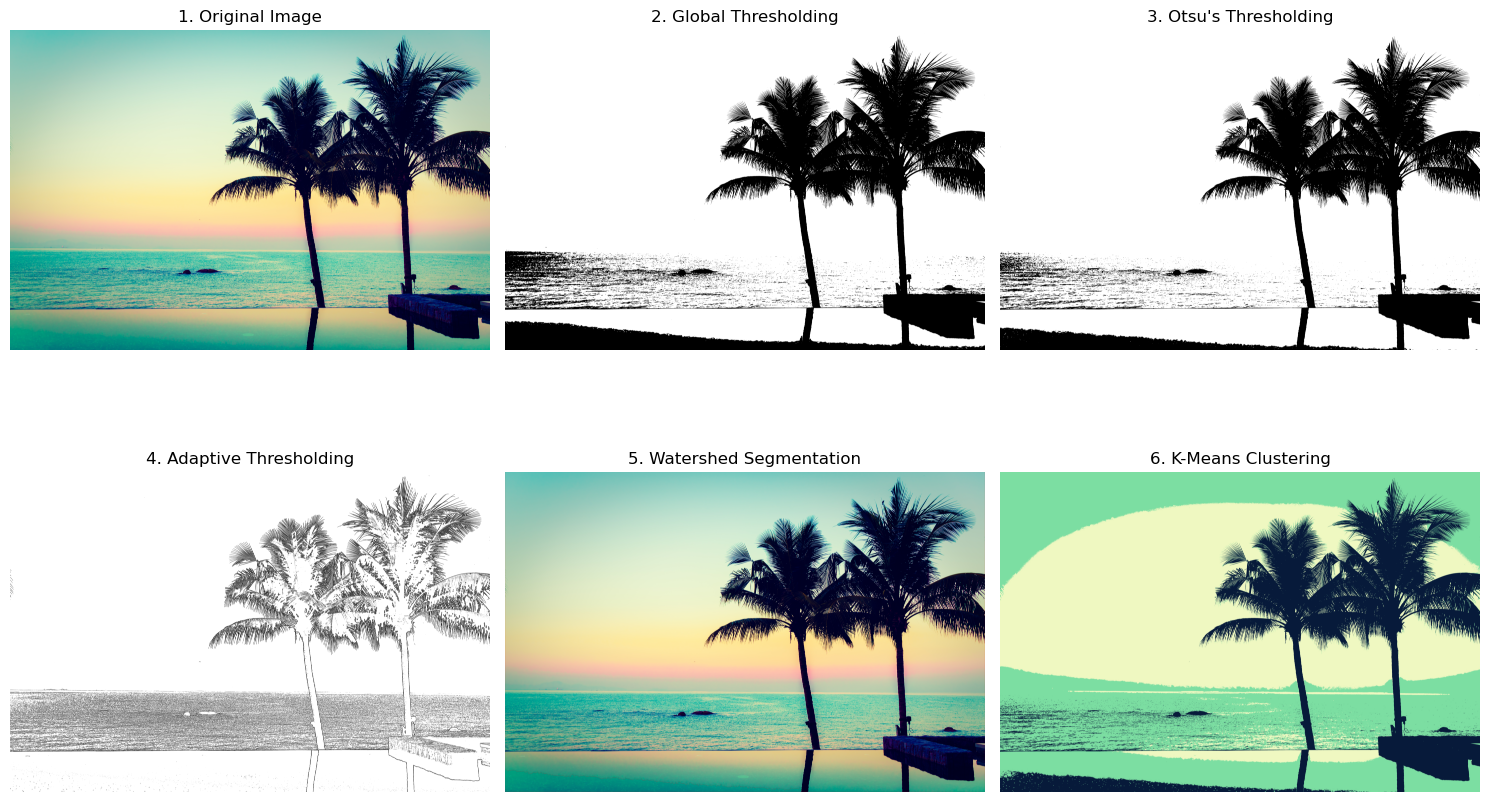

In [8]:
# 8 & 9. Comparative Visualization Plot
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].imshow(img_rgb)
axes[0, 0].set_title("1. Original Image")
axes[0, 0].axis('off')

axes[0, 1].imshow(thresh_global, cmap='gray')
axes[0, 1].set_title("2. Global Thresholding")
axes[0, 1].axis('off')

axes[0, 2].imshow(thresh_otsu, cmap='gray')
axes[0, 2].set_title("3. Otsu's Thresholding")
axes[0, 2].axis('off')

axes[1, 0].imshow(thresh_adaptive, cmap='gray')
axes[1, 0].set_title("4. Adaptive Thresholding")
axes[1, 0].axis('off')

axes[1, 1].imshow(img_watershed_output)
axes[1, 1].set_title("5. Watershed Segmentation")
axes[1, 1].axis('off')

axes[1, 2].imshow(img_kmeans)
axes[1, 2].set_title("6. K-Means Clustering")
axes[1, 2].axis('off')

plt.tight_layout()
plt.show()



## Question 1: What is image segmentation? Why is it considered a fundamental step in computer vision?

* Answer: Image segmentation is the process of partitioning a digital image into multiple distinct, non-overlapping regions or sets of pixels based on shared characteristics like intensity, color, texture, or edges.
* Why it is fundamental: Raw images contain unstructured grids of pixels. Segmentation acts as the critical bridge between low-level pixel data and high-level visual understanding. By isolating regions of interest (ROIs) and filtering out irrelevant background noise, it simplifies the image data. This makes downstream tasks—such as object detection, tracking, and feature extraction—significantly more accurate and computationally efficient.

------------------------------
## Question 2: Differentiate between Image Segmentation and Image Classification.

* Answer: They differ primarily in their structural granularity and objective:

| Feature | Image Segmentation | Image Classification |
|---|---|---|
| Objective | Divides an image into precise spatial regions or pixels belonging to an object. | Assigns a single categorical label to the entire input image. |
| Output | A pixel-level mask or boundary outlining where objects are located. | A class label (e.g., "Cat", "Car") along with a confidence score. |
| Granularity | High granularity (operates at the individual pixel level). | Low granularity (operates at the global scene level). |

------------------------------
## Question 3: Explain the working principle of Global Thresholding, Otsu's Thresholding, and Adaptive Thresholding.

* Answer:
* Global Thresholding: Uses a single fixed threshold value (T) across the entire image. Any pixel with an intensity greater than T is assigned to the foreground (e.g., 255/white), and any pixel below T is assigned to the background (e.g., 0/black). It is computationally fast but fails when images have uneven lighting.
* Otsu's Thresholding: An automatic global thresholding technique. It analyzes the image's intensity histogram and mathematically selects the optimal threshold value by maximizing the variance between classes (foreground and background), minimizing their internal variance. It works best on distinct bimodal histograms.
* Adaptive Thresholding: Calculates a separate threshold value for every individual pixel based on the intensity distribution of its small local neighborhood (e.g., an 11 × 11 block). This allows the threshold to dynamically adjust across the image, making it highly effective for handling shadows, gradients, and uneven illumination.

------------------------------
## Question 4: What is the Watershed Algorithm? Why is it useful for separating overlapping objects?

* Answer:
* Working Principle: The Watershed Algorithm treats a grayscale image like a topographic surface, where high pixel intensities represent ridges/mountains and low intensities represent valleys/basins. The algorithm conceptually "floods" these basins with water from local minima. Where the rising water from different basins meets, dams (watershed lines) are built to form boundaries.
* Why it isolates overlapping objects: Standard thresholding blends touching objects into a single blob. The watershed algorithm uses a distance transform (calculating the distance from every foreground pixel to the nearest background pixel) to find the unique center/peak of each touching object. It treats these peaks as distinct starting points (markers) for the flooding process, successfully drawing clean dividing boundaries right where the objects collide.

------------------------------
## Question 5: How is K-Means Clustering applied to image segmentation?

* Answer: K-Means is an unsupervised machine learning algorithm applied to color-based segmentation.


   1. The image is flattened into a dataset of pixels, where each pixel is represented by its feature vector (e.g., Red, Green, and Blue values).
   2. The user specifies K, the desired number of color segments.
   3. The algorithm iteratively clusters pixels into K groups based on their Euclidean distance in the color space.
   4. Once converged, every pixel in a cluster is replaced with the mean color (centroid) of that cluster. This compresses the image's color palette and isolates objects with distinct color profiles from their surroundings.

------------------------------
## Question 6: Compare threshold-based segmentation and clustering-based segmentation techniques.

* Answer:

| Feature | Threshold-based Segmentation | Clustering-based Segmentation (e.g., K-Means) |
|---|---|---|
| Input Type | Primarily works on grayscale (1D) data. | Works naturally on multidimensional color space data (RGB/HSV). |
| Human Input | Requires manual selection of T (unless using Otsu's). | Requires the user to define the number of clusters (K). |
| Complexity | Mathematically simple, highly efficient, and fast. | Iterative process, computationally heavier for large images. |
| Best Used For | High-contrast scenes with simple backgrounds. | Complex, multi-colored natural scenes. |

------------------------------
## Question 7: What challenges are encountered while segmenting images with complex backgrounds or varying illumination?

* Answer:
* Varying Illumination: Shadows, light gradients, and reflections skew pixel intensity profiles. A pixel belonging to the foreground in a shadowed area might look darker than a background pixel in a well-lit area, causing global threshold methods to fail completely.
* Complex Backgrounds: High texture variations, cluttered environments, and low contrast between the target object and the background make it difficult for mathematical boundary or intensity formulas to separate the region of interest cleanly. This often leads to over-segmentation (chopping an object into fragments) or under-segmentation (merging the object into the background).

------------------------------
## Question 8: Mention five real-world applications where image segmentation plays a critical role.

* Answer:
* Medical Image Analysis: Isolating tumors, blood vessels, or organs from MRI/CT scans to assist in automated disease diagnosis.
* Autonomous Driving: Segmenting real-time video feeds into drivable roads, pedestrians, lane markings, and traffic signs for navigation safety.
* Satellite and Remote Sensing: Identifying crop fields, water bodies, deforestation patterns, and urban growth from satellite imagery.
* Industrial Quality Inspection: Spotting microscopic cracks, surface defects, or component misalignments on assembly lines.
* Biometric Authentication: Extracting the precise boundaries of irises or fingerprint ridges for security scanning systems.

------------------------------
## Question 9: How does image segmentation improve the performance of object detection and image recognition systems?

* Answer: Standard object detection uses rectangular bounding boxes, which often include irrelevant background pixels. Image segmentation refines this by providing pixel-level masks. By isolating the exact geometry of the object, it filters out distracting background noise. This clean data input ensures that recognition systems extract features only from the object itself, drastically reducing false positives and improving the classification accuracy of highly complex structures.

------------------------------
## Question 10: Compare traditional image segmentation techniques with deep learning-based segmentation methods such as U-Net and Mask R-CNN.

* Answer:

| Feature | Traditional Techniques (OpenCV) | Deep Learning Techniques (U-Net / Mask R-CNN) |
|---|---|---|
| Feature Extraction | Relies on hand-crafted rules (intensities, gradients, edges). | Automatically learns complex spatial and semantic features from data. |
| Data & Training | Requires no training data or GPU acceleration. | Requires massive labeled datasets and heavy GPU training. |
| Contextual Awareness | Poor; looks strictly at local pixel values and lacks semantic understanding. | High; understands what the object is globally before masking it. |
| Robustness | Struggles heavily with complex scenes and environmental changes. | Highly robust to variations in lighting, scaling, and occlusion. |



